# Wireless Communication Networks and Systems
## LAB 01: Fundamentals of Signal Transmission
*Python simulation*

---
### Learning Objectives
At the end of this lab, students will be able to:
- Generate and visualize a simple signal (sine wave).
- Understand the effects of attenuation, noise, and delay on transmission.
- Use the FFT (Fast Fourier Transform) to analyze a signal in the frequency domain.
- Relate these effects to real-world wireless systems (Wi-Fi, IoT, satellite).

### Theoretical Background
A signal is a variation over time (e.g., an electrical wave). When it passes through a channel (air, cable, fiber), it may experience:
- **Attenuation** – amplitude decreases (e.g., power loss over distance).
- **Noise** – interference is added (e.g., thermal noise, radio interference).
- **Delay** – it arrives with a temporal shift (e.g., satellite communications).

In practice, a channel is often a combination of these effects.

### Required Tools
- Python 3 with `numpy` and `matplotlib`.

---
## Step 1 – Generate a sine wave

A sine wave is defined as:
$$s(t) = A \cdot \sin(2\pi f t)$$

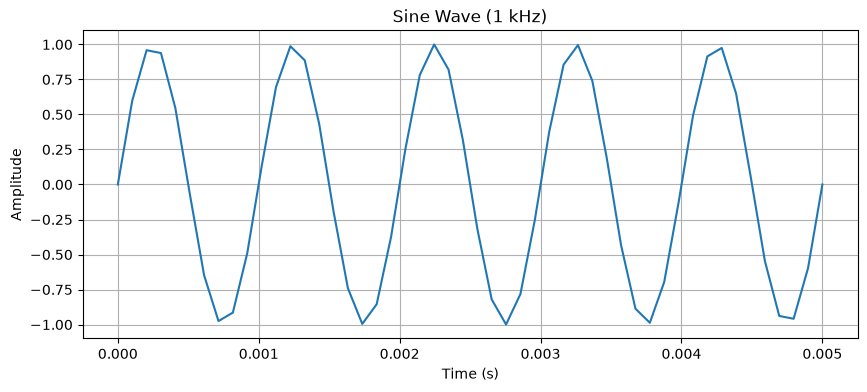

In [31]:
import numpy as np
import matplotlib.pyplot as plt

fs = 10000 # sampling frequency (Hz)
f = 1000 # signal frequency (Hz)
A = 1 # amplitude
t = np.linspace(0, 0.005, int(fs*0.005)) # 5 ms

signal = A * np.sin(2*np.pi*f*t)

plt.figure(figsize=(10,4))
plt.plot(t, signal)
plt.title("Sine Wave (1 kHz)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

### Task
Change the frequency to 500 Hz and 2000 Hz. What happens?

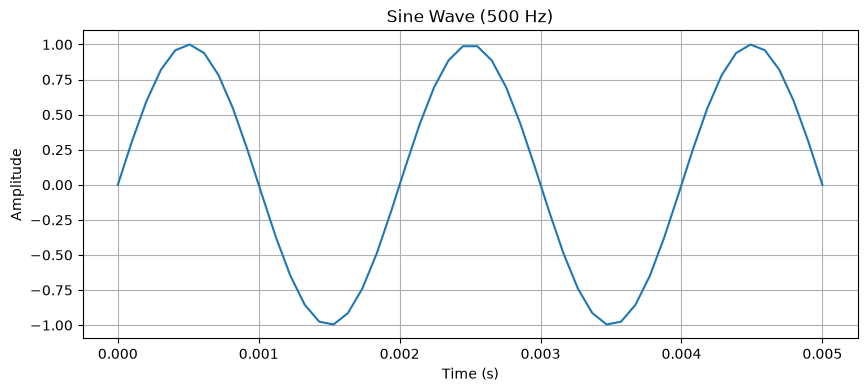

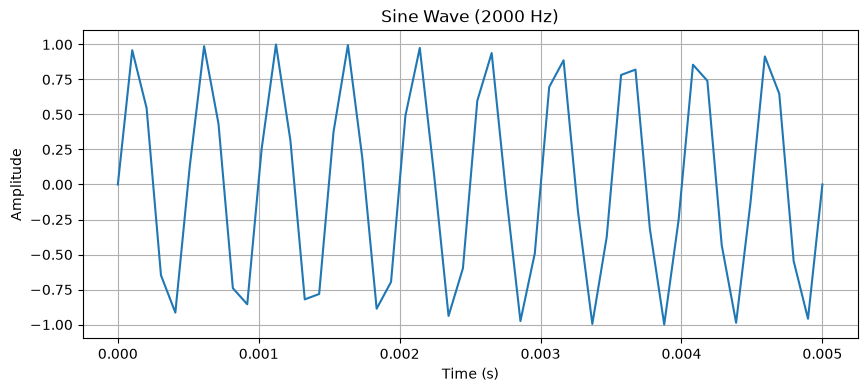

In [32]:
# Task: Change frequency to 500 Hz and 2000 Hz
f_500 = 500 # change frequency to 500 Hz
signal_500Hz = A * np.sin(2*np.pi*f_500*t)
plt.figure(figsize=(10,4))
plt.plot(t, signal_500Hz)
plt.title("Sine Wave (500 Hz)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

f_2000 = 2000 # change frequency to 2000 Hz  
signal_2000Hz = A * np.sin(2*np.pi*f_2000*t)
plt.figure(figsize=(10,4))
plt.plot(t, signal_2000Hz)
plt.title("Sine Wave (2000 Hz)")
plt.xlabel("Time (s)") 
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()




**Observation / Answer:**
Lower frequency gives fewer cycles in the same time. Higher frequency gives more cycles; the amplitude stays the same.

---
## Step 2 – Frequency Analysis (FFT)

The FFT decomposes a signal into its frequencies.

Sampling frequency: 1000 Hz


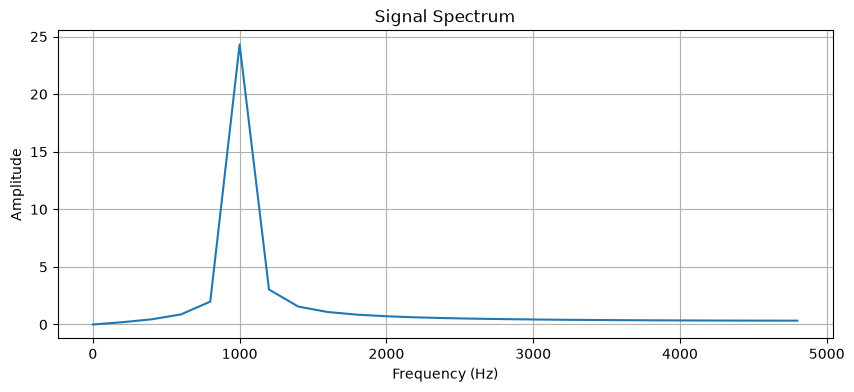

In [ ]:

fft_signal = np.fft.fft(signal)
freqs = np.fft.fftfreq(len(signal), 1/fs)

plt.figure(figsize=(10,4))
plt.plot(freqs[:len(freqs)//2], np.abs(fft_signal[:len(freqs)//2]))
plt.title("Signal Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

### Question
Identify the dominant frequency in the spectrum.

**Answer:** The dominant frequency is about 1 kHz.

---
## Step 3 – Attenuation

We simulate power loss by scaling the signal.

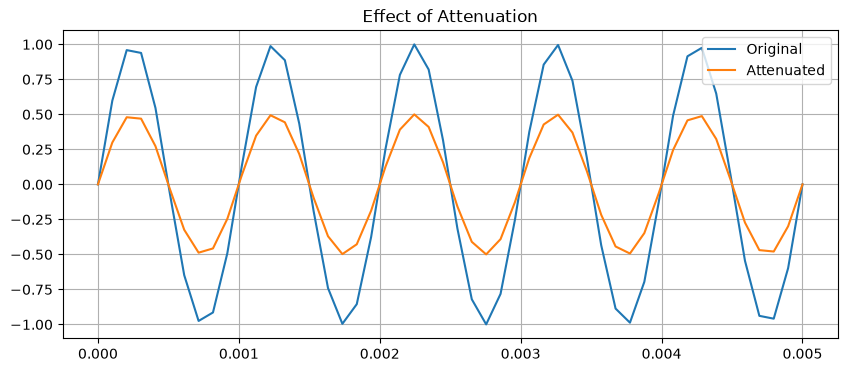

In [34]:
attenuated = 0.5 * signal

plt.figure(figsize=(10,4))
plt.plot(t, signal, label="Original")
plt.plot(t, attenuated, label="Attenuated")
plt.legend()
plt.title("Effect of Attenuation")
plt.grid(True)
plt.show()

### Question
Why is attenuation problematic for Wi-Fi?

**Answer:** Attenuation reduces the signal strength, making Wi-Fi more difficult to detect and increasing errors or reducing range.

---
## Step 4 – Add Noise

We add Gaussian noise.

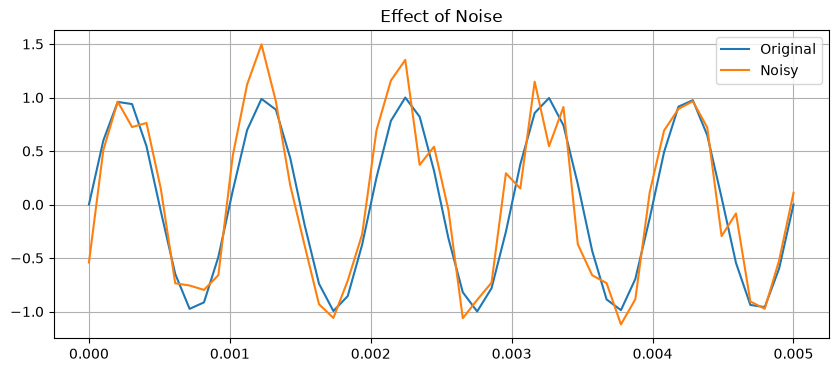

In [35]:
sigma = 0.3
noise = np.random.normal(0, sigma, len(t))
noisy_signal = signal + noise

plt.figure(figsize=(10,4))
plt.plot(t, signal, label="Original")
plt.plot(t, noisy_signal, label="Noisy")
plt.legend()
plt.title("Effect of Noise")
plt.grid(True)
plt.show()

### Task & Question
- **Task:** Vary $\sigma$ (0.1, 0.5, 1.0) and observe.
- **Question:** Why can the FFT still recover the main frequency under noise?

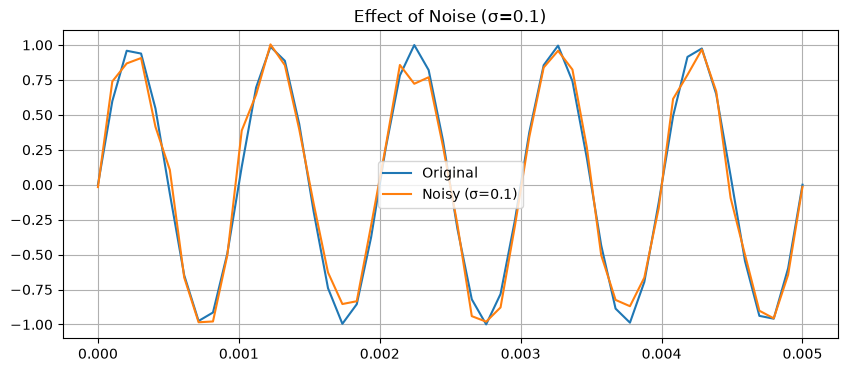

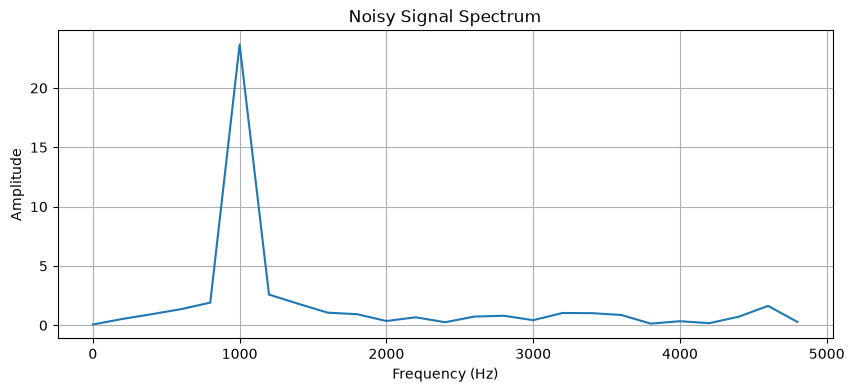

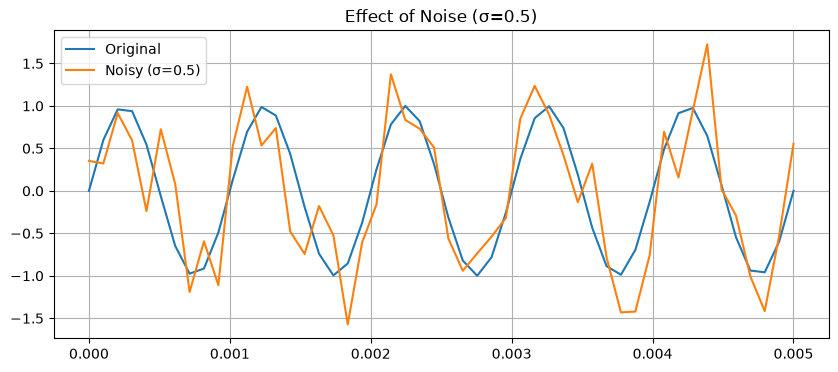

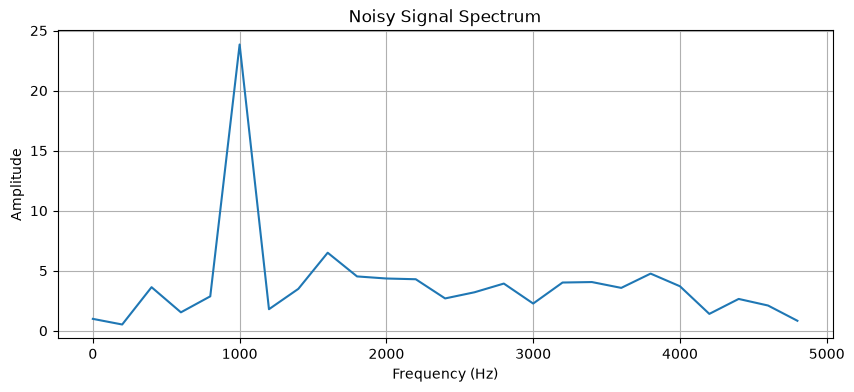

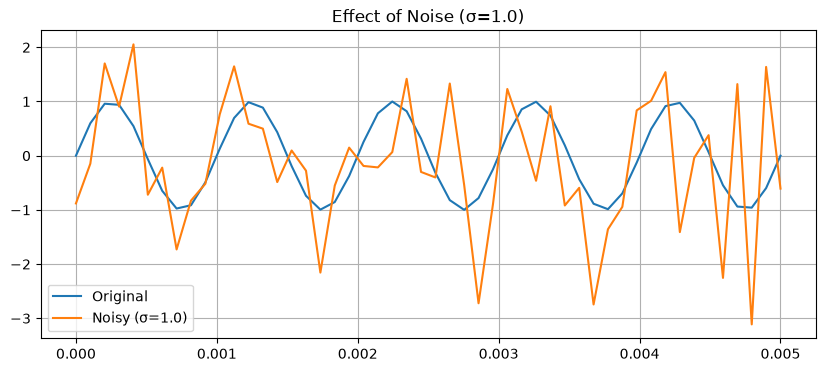

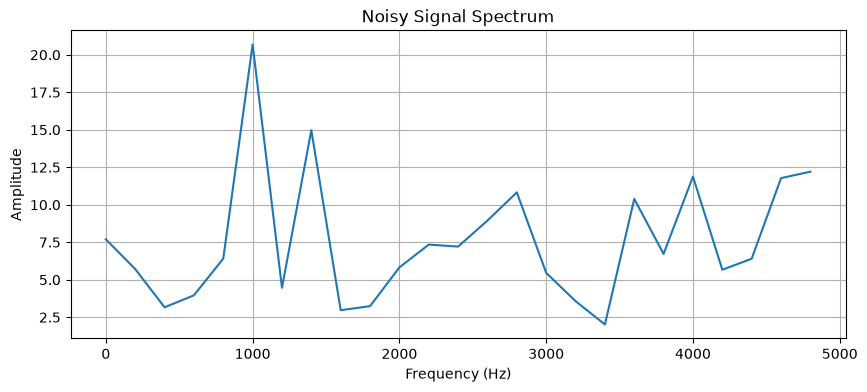

In [36]:
# Task: Vary sigma (0.1, 0.5, 1.0) and observe
sigma_values = [0.1, 0.5, 1.0]
for sigma in sigma_values:
    noise = np.random.normal(0, sigma, len(t))
    noisy_signal = signal + noise

    plt.figure(figsize=(10,4))
    plt.plot(t, signal, label="Original")
    plt.plot(t, noisy_signal, label=f"Noisy (σ={sigma})")
    plt.legend()
    plt.title(f"Effect of Noise (σ={sigma})")
    plt.grid(True)
    plt.show()
    fft_noisy_signal = np.fft.fft(noisy_signal)
    plt.figure(figsize=(10,4))
    plt.plot(freqs[:len(freqs)//2], np.abs(fft_noisy_signal[:len(freqs)//2]))
    plt.title("Noisy Signal Spectrum")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()




**Answer:** As sigma increases, the signal becomes noisier. The FFT can still show the main frequency because the sinusoid creates a strong spectral peak while random noise is spread across many frequencies.

---
## Step 5 – Delay

We introduce a time shift.

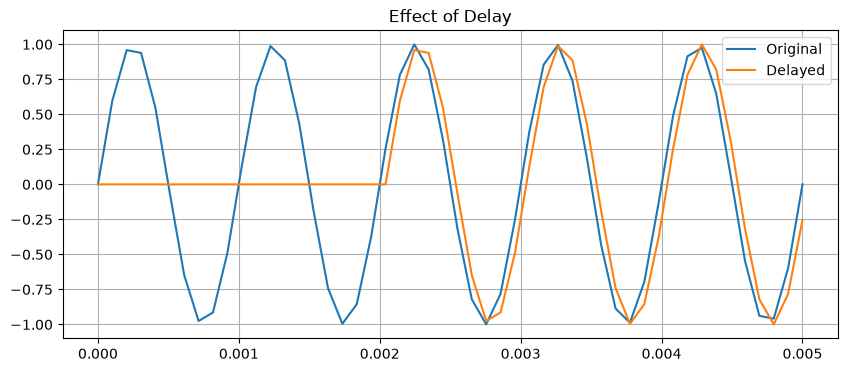

In [41]:
delay = 20
delayed_signal = np.concatenate((np.zeros(delay), signal[:-delay]))

plt.figure(figsize=(10,4))
plt.plot(t, signal, label="Original")
plt.plot(t, delayed_signal, label="Delayed")
plt.legend()
plt.title("Effect of Delay")
plt.grid(True)
plt.show()

### Question
Give a real example where delay is significant.

**Answer:** Satellite communication is a real example because signals travel long distances and experience noticeable propagation delay.

---
## Step 6 – Combined Channel

We combine attenuation, noise, and delay.

In [ ]:
attenuation = 0.6
sigma = 0.3
delay = 100

modified = attenuation * signal
modified += np.random.normal(0, sigma, len(t))
modified = np.concatenate((np.zeros(delay), modified[:-delay]))

plt.figure(figsize=(10,4))
plt.plot(t, signal, label="Original")
plt.plot(t, modified, label="After Channel")
plt.legend()
plt.title("Signal through a Channel")
plt.grid(True)
plt.show()

### Question
Compare the original and received signals.

**Answer:** The received signal is delayed, weaker, and noisy compared with the original signal.

---
## Step 7 – Square Wave Variant

Generate a square wave variant using `np.sign`.

In [ ]:
square_wave = np.sign(np.sin(2*np.pi*f*t))

plt.figure(figsize=(10,4))
plt.plot(t[:200], square_wave[:200])
plt.title("Square Wave (1 kHz)")
plt.grid(True)
plt.show()

### Question
Why does a square wave require more bandwidth than a sine wave?

**Answer:** A square wave contains the fundamental frequency plus many odd harmonics, so it occupies more bandwidth than a single sine wave.